In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("./short_term_stability.tsv", sep="\t")
df = df[(df["sample_size"] >= 100) & (df["median_delta_t"] <= 60 * 60 * 24)]
print(df.shape)

(44218, 10)


In [2]:
# Define the r_history values to filter
r_history_values = ["1", "2", "3", "1,2", "1,3", "3,2"]

# Group by user_id and filter
filtered_user_ids = df.groupby("user").filter(
    lambda x: all(item in x["r_history"].values for item in r_history_values)
)

# Extract the user_ids
filtered_user_ids = filtered_user_ids["user"].unique()

# Filter the original DataFrame to keep only the filtered user_ids
df = df[df["user"].isin(filtered_user_ids)]

print(df.shape)

(4211, 10)


In [3]:
print("Unit: minutes\n")

# Convert to minutes
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

print("First Rating: Again")
print(
    df_display[(df_display["r_history"] == "1")][
        ["average_retention", "median_delta_t", "stability"]
    ].agg(["mean", "median", "std"])
)
print("First Rating: Hard")
print(
    df_display[(df_display["r_history"] == "2")][
        ["average_retention", "median_delta_t", "stability"]
    ].agg(["mean", "median", "std"])
)
print("First Rating: Good")
print(
    df_display[(df_display["r_history"] == "3")][
        ["average_retention", "median_delta_t", "stability"]
    ].agg(["mean", "median", "std"])
)

Unit: minutes

First Rating: Again
        average_retention  median_delta_t   stability
mean             0.739363       13.108612   16.424546
median           0.751700        1.866667    0.666667
std              0.137183       82.279276  175.927533
First Rating: Hard
        average_retention  median_delta_t    stability
mean             0.925156       66.676090   767.334842
median           0.939200        7.800000    41.316667
std              0.058914      234.507632  3371.697214
First Rating: Good
        average_retention  median_delta_t     stability
mean             0.961623       84.752307   3856.110496
median           0.972050       12.666667    496.158333
std              0.040648      257.828249  16322.443190


In [4]:
print("Unit: minutes\n")

# Convert to minutes
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

print(
    df_display[(df_display["r_history"] == "1")][
        ["average_retention", "median_delta_t", "stability"]
    ].quantile(np.linspace(0, 1, 11))
)
print(
    df_display[(df_display["r_history"] == "2")][
        ["average_retention", "median_delta_t", "stability"]
    ].quantile(np.linspace(0, 1, 11))
)
print(
    df_display[(df_display["r_history"] == "3")][
        ["average_retention", "median_delta_t", "stability"]
    ].quantile(np.linspace(0, 1, 11))
)

Unit: minutes

     average_retention  median_delta_t    stability
0.0            0.20980        0.333333     0.016667
0.1            0.54108        1.380000     0.066667
0.2            0.62570        1.500000     0.160000
0.3            0.68658        1.600000     0.300000
0.4            0.72782        1.703333     0.450000
0.5            0.75170        1.866667     0.666667
0.6            0.79260        2.230000     0.930000
0.7            0.81866        2.830000     1.333333
0.8            0.85738        4.566667     2.216667
0.9            0.90680       10.603333     5.186667
1.0            0.99340     1306.450000  2879.666667
     average_retention  median_delta_t     stability
0.0            0.70390        0.550000      1.100000
0.1            0.84744        6.333333      7.226667
0.2            0.87676        6.833333     13.636667
0.3            0.90000        7.066667     21.846667
0.4            0.92440        7.366667     30.053333
0.5            0.93920        7.800000     

In [5]:
print("Unit: minutes\n")

# Convert to minutes
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

print(
    df_display[(df_display["r_history"] == "1,3")][
        ["average_retention", "median_delta_t", "stability"]
    ].agg(["mean", "median", "std"])
)
print(
    df_display[(df_display["r_history"] == "1,3")][
        ["average_retention", "median_delta_t", "stability"]
    ].quantile(np.linspace(0, 1, 11))
)

Unit: minutes

        average_retention  median_delta_t   stability
mean             0.917805       95.185564  388.317848
median           0.928400       12.691667   75.816667
std              0.061591      285.012364  969.740370
     average_retention  median_delta_t    stability
0.0            0.59760        0.316667     0.900000
0.1            0.83720        8.633333    10.450000
0.2            0.87920       11.233333    20.196667
0.3            0.90053       11.916667    30.906667
0.4            0.91460       12.300000    53.433333
0.5            0.92840       12.691667    75.816667
0.6            0.94196       13.536667   124.313333
0.7            0.95567       15.696667   209.061667
0.8            0.96926       22.380000   363.896667
0.9            0.98476       82.336667  1037.995000
1.0            1.00000     1415.600000  8887.850000


In [6]:
print("Unit: minutes\n")

# Convert to minutes
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

print(
    df_display[(df_display["r_history"] == "1,2")][
        ["average_retention", "median_delta_t", "stability"]
    ].agg(["mean", "median", "std"])
)
print(
    df_display[(df_display["r_history"] == "1,2")][
        ["average_retention", "median_delta_t", "stability"]
    ].quantile(np.linspace(0, 1, 11))
)

Unit: minutes

        average_retention  median_delta_t   stability
mean             0.859692       78.393137   82.467081
median           0.871800        8.133333   11.958333
std              0.078928      260.196334  351.422381
     average_retention  median_delta_t    stability
0.0            0.54390        0.133333     0.333333
0.1            0.75479        6.385000     2.335000
0.2            0.79664        6.886667     4.616667
0.3            0.82900        7.200000     7.005000
0.4            0.85052        7.490000     9.106667
0.5            0.87180        8.133333    11.958333
0.6            0.88940        8.903333    16.476667
0.7            0.90571       10.478333    25.980000
0.8            0.93038       13.570000    48.326667
0.9            0.95300       36.916667   116.366667
1.0            1.00000     1394.466667  3847.916667


In [7]:
print("Unit: minutes\n")

# Convert to minutes
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

print(
    df_display[(df_display["r_history"] == "3,2")][
        ["average_retention", "median_delta_t", "stability"]
    ].agg(["mean", "median", "std"])
)
print(
    df_display[(df_display["r_history"] == "3,2")][
        ["average_retention", "median_delta_t", "stability"]
    ].quantile(np.linspace(0, 1, 11))
)

Unit: minutes

        average_retention  median_delta_t    stability
mean             0.952981        90.82812  1436.165944
median           0.964100        13.15000   309.183333
std              0.042224       276.10461  4401.234818
     average_retention  median_delta_t     stability
0.0            0.70940        0.033333      3.933333
0.1            0.89656        7.066667     29.763333
0.2            0.92554       11.106667     55.560000
0.3            0.94072       11.935000     87.626667
0.4            0.95268       12.483333    172.846667
0.5            0.96410       13.150000    309.183333
0.6            0.97240       14.413333    607.960000
0.7            0.98033       18.180000   1049.795000
0.8            0.98906       24.373333   1713.306667
0.9            0.99450      107.558333   3069.095000
1.0            1.00000     1439.783333  71820.916667


In [8]:
# Calculate linear relationship between Hard (rating=2) stability and Again (rating=1) & Good (rating=3) stability
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_percentage_error

# Convert to minutes for display
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

# Get all users
unique_users = df["user"].unique()

# Prepare data: each row represents a user with their stability values for different ratings
stability_data = []

for user in unique_users:
    user_data = df_display[df_display["user"] == user]

    # Extract stability for different ratings
    rating_1 = user_data[user_data["r_history"] == "1"]["stability"].values
    rating_2 = user_data[user_data["r_history"] == "2"]["stability"].values
    rating_3 = user_data[user_data["r_history"] == "3"]["stability"].values

    # Only include users who have all three ratings
    if len(rating_1) > 0 and len(rating_2) > 0 and len(rating_3) > 0:
        stability_data.append(
            {
                "user": user,
                "stability_again": rating_1[0],
                "stability_hard": rating_2[0],
                "stability_good": rating_3[0],
            }
        )

# Create DataFrame
stability_df = pd.DataFrame(stability_data)

print(f"Number of users with all three ratings: {len(stability_df)}")
print("\n" + "=" * 80)
print("Linear relationship between Hard stability and Again stability")
print("=" * 80)

X = stability_df[["stability_again"]].values
y = stability_df["stability_hard"].values

# Fit standard linear regression (with intercept)
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)
r2 = r2_score(y, y_pred)
mape = mean_absolute_percentage_error(y, y_pred)

print(
    f"\nModel: stability_hard = {reg.coef_[0]:.6f} * stability_again + {reg.intercept_:.6f}"
)
print(f"R² score: {r2:.6f}")
print(f"MAPE: {mape:.6f}")
print(f"Coefficient (slope): {reg.coef_[0]:.6f}")
print(f"Intercept: {reg.intercept_:.6f}")

# Calculate correlation
correlation = np.corrcoef(y, X.ravel())[0, 1]
print(f"\nCorrelation coefficient: {correlation:.6f}")

print("\n" + "=" * 80)
print("Linear relationship between Hard stability and Good stability")
print("=" * 80)

X = stability_df[["stability_good"]].values
y = stability_df["stability_hard"].values

# Fit standard linear regression (with intercept)
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)
r2 = r2_score(y, y_pred)
mape = mean_absolute_percentage_error(y, y_pred)

print(
    f"\nModel: stability_hard = {reg.coef_[0]:.6f} * stability_good + {reg.intercept_:.6f}"
)
print(f"R² score: {r2:.6f}")
print(f"MAPE: {mape:.6f}")
print(f"Coefficient (slope): {reg.coef_[0]:.6f}")
print(f"Intercept: {reg.intercept_:.6f}")

# Calculate correlation
correlation = np.corrcoef(y, X.ravel())[0, 1]
print(f"\nCorrelation coefficient: {correlation:.6f}")

print("\n" + "=" * 80)
print("Multiple linear regression: Hard stability vs. Again and Good stability")
print("=" * 80)

X = stability_df[["stability_again", "stability_good"]].values
y = stability_df["stability_hard"].values

# Fit standard multiple linear regression (with intercept)
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)
r2 = r2_score(y, y_pred)
mape = mean_absolute_percentage_error(y, y_pred)

print(
    f"\nModel: stability_hard = {reg.coef_[0]:.6f} * stability_again + {reg.coef_[1]:.6f} * stability_good + {reg.intercept_:.6f}"
)
print(f"R² score: {r2:.6f}")
print(f"MAPE: {mape:.6f}")
print(f"Coefficient for Again: {reg.coef_[0]:.6f}")
print(f"Coefficient for Good: {reg.coef_[1]:.6f}")
print(f"Intercept: {reg.intercept_:.6f}")

# Print some statistics
print("\n" + "=" * 80)
print("Summary Statistics (in minutes)")
print("=" * 80)
print(stability_df[["stability_again", "stability_hard", "stability_good"]].describe())

Number of users with all three ratings: 422

Linear relationship between Hard stability and Again stability

Model: stability_hard = 5.971372 * stability_again + 624.010959
R² score: 0.057823
MAPE: 33.057254
Coefficient (slope): 5.971372
Intercept: 624.010959

Correlation coefficient: 0.240464

Linear relationship between Hard stability and Good stability

Model: stability_hard = 0.098522 * stability_good + 242.237849
R² score: 0.280498
MAPE: 15.518023
Coefficient (slope): 0.098522
Intercept: 242.237849

Correlation coefficient: 0.529621

Multiple linear regression: Hard stability vs. Again and Good stability

Model: stability_hard = 5.658472 * stability_again + 0.097503 * stability_good + 185.787545
R² score: 0.332390
MAPE: 12.588299
Coefficient for Again: 5.658472
Coefficient for Good: 0.097503
Intercept: 185.787545

Summary Statistics (in minutes)
       stability_again  stability_hard  stability_good
count       422.000000      422.000000      422.000000
mean         10.791864     

In [9]:
# Constrained multiple regression: coefficients sum to 1 (no intercept)
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_percentage_error

X = stability_df[["stability_again", "stability_good"]].values
y = stability_df["stability_hard"].values

# Solve: minimize ||y - X b||^2 subject to 1^T b = 1
# Using Lagrange multipliers: [2 X^T X   1] [b]   [2 X^T y]
#                               [1^T     0] [λ] = [1]
XtX = X.T @ X
Xty = X.T @ y
ones = np.ones((X.shape[1], 1))

A = np.block([[2 * XtX, ones], [ones.T, np.zeros((1, 1))]])
rhs = np.concatenate([2 * Xty, np.array([1.0])])

try:
    sol = np.linalg.solve(A, rhs)
except np.linalg.LinAlgError:
    sol, *_ = np.linalg.lstsq(A, rhs, rcond=None)

beta = sol[: X.shape[1]]
lam = sol[-1]

y_pred = X @ beta
r2 = r2_score(y, y_pred)
mape = mean_absolute_percentage_error(y, y_pred)

print("Constrained multiple regression (sum of coefficients = 1, no intercept)")
print(f"Coefficients: Again={beta[0]:.6f}, Good={beta[1]:.6f}")
print(f"Sum of coefficients: {beta.sum():.6f}")
print(f"R² score: {r2:.6f}")
print(f"MAPE: {mape:.6f}")

Constrained multiple regression (sum of coefficients = 1, no intercept)
Coefficients: Again=0.899075, Good=0.100925
Sum of coefficients: 1.000000
R² score: 0.291474
MAPE: 2.974016


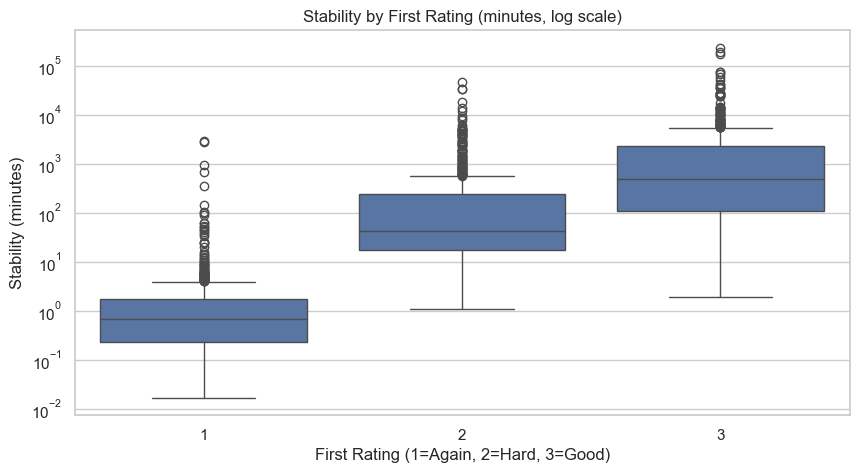

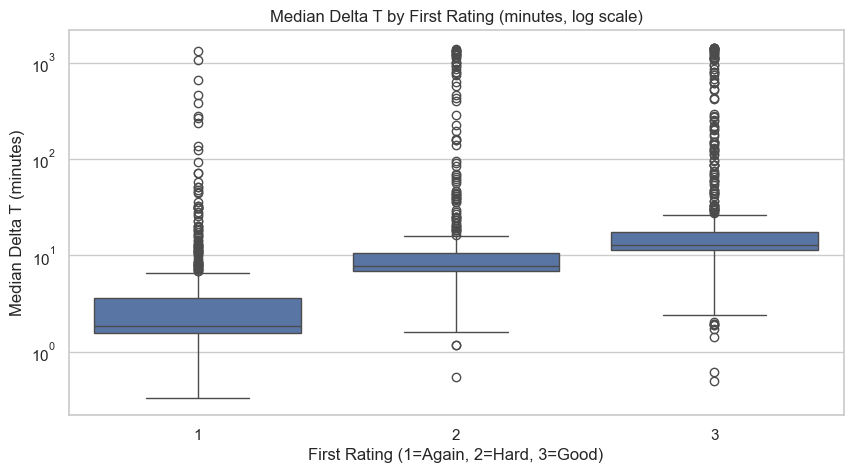

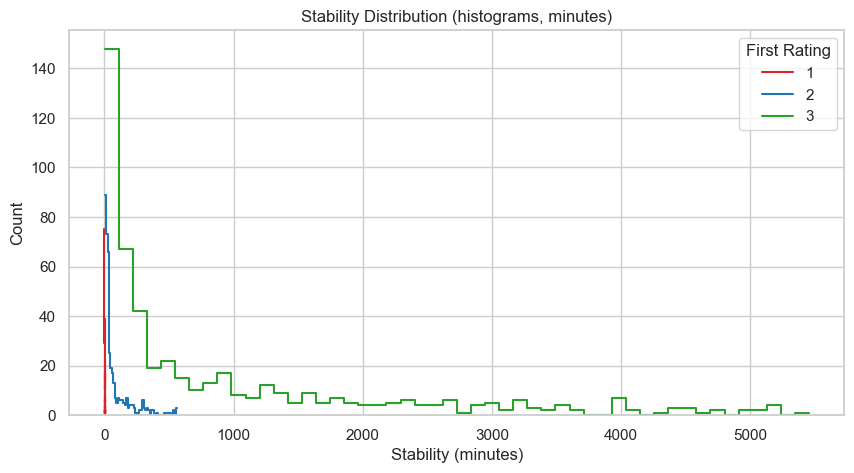

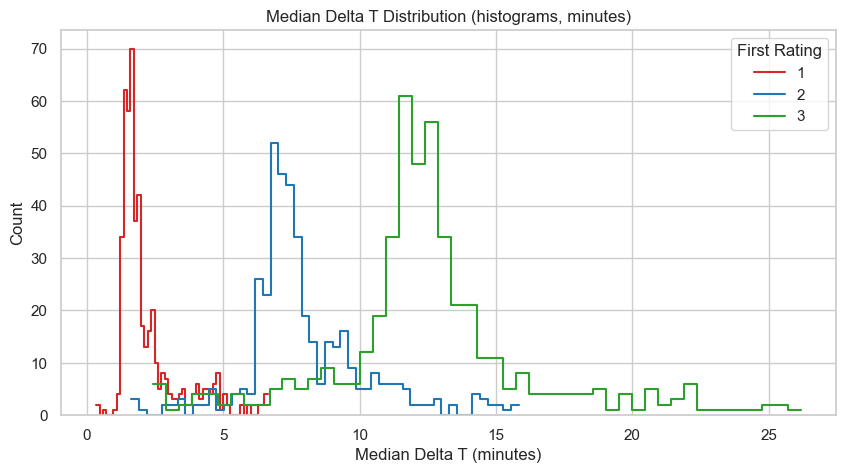

In [10]:
# Visualize distribution statistics as images (minutes)
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare display data (minutes)
df_display = df.copy()
df_display["median_delta_t"] = df_display["median_delta_t"] / 60
df_display["stability"] = df_display["stability"] / 60

# Focused r_history groups
groups_main = ["1", "2", "3"]
groups_pairs = ["1,2", "1,3", "3,2"]

# Set style
sns.set(style="whitegrid")

# 1) Boxplots for stability by rating (Again/Hard/Good)
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_display[df_display["r_history"].isin(groups_main)],
    x="r_history",
    y="stability",
    order=groups_main,
)
plt.yscale("log")
plt.title("Stability by First Rating (minutes, log scale)")
plt.xlabel("First Rating (1=Again, 2=Hard, 3=Good)")
plt.ylabel("Stability (minutes)")
plt.show()

# 2) Boxplots for median_delta_t by rating (Again/Hard/Good)
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_display[df_display["r_history"].isin(groups_main)],
    x="r_history",
    y="median_delta_t",
    order=groups_main,
)
plt.yscale("log")
plt.title("Median Delta T by First Rating (minutes, log scale)")
plt.xlabel("First Rating (1=Again, 2=Hard, 3=Good)")
plt.ylabel("Median Delta T (minutes)")
plt.show()

# 3) Histograms for stability across ratings (Again/Hard/Good)
plt.figure(figsize=(10, 5))
for g, color in zip(groups_main, ["#d62728", "#1f77b4", "#2ca02c"]):
    vals = df_display[df_display["r_history"] == g]["stability"]
    q1, q3 = np.percentile(vals, 25), np.percentile(vals, 75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    subset = vals[(vals >= max(lower, 1e-6)) & (vals <= upper)]
    sns.histplot(
        subset,
        bins=50,
        element="step",
        fill=False,
        label=f"{g}",
        color=color,
        stat="count",
    )
# plt.xscale("log")
plt.title("Stability Distribution (histograms, minutes)")
plt.xlabel("Stability (minutes)")
plt.ylabel("Count")
plt.legend(title="First Rating")
plt.show()

# 4) Histograms for median_delta_t across ratings (Again/Hard/Good)
plt.figure(figsize=(10, 5))
for g, color in zip(groups_main, ["#d62728", "#1f77b4", "#2ca02c"]):
    vals = df_display[df_display["r_history"] == g]["median_delta_t"]
    q1, q3 = np.percentile(vals, 25), np.percentile(vals, 75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    subset = vals[(vals >= max(lower, 1e-6)) & (vals <= upper)]
    sns.histplot(
        subset,
        bins=50,
        element="step",
        fill=False,
        label=f"{g}",
        color=color,
        stat="count",
    )
# plt.xscale("log")
plt.title("Median Delta T Distribution (histograms, minutes)")
plt.xlabel("Median Delta T (minutes)")
plt.ylabel("Count")
plt.legend(title="First Rating")
plt.show()

Per-user constrained coefficients on [0,1] with sum=1
       beta_again   beta_good  beta_sum
count  422.000000  422.000000     422.0
mean     0.777729    0.222271       1.0
std      0.275512    0.275512       0.0
min      0.000000    0.000549       1.0
25%      0.708358    0.046204       1.0
50%      0.894048    0.105952       1.0
75%      0.953796    0.291642       1.0
max      0.999451    1.000000       1.0

Within [0,1] check:
Proportion inside bounds: 1.000000


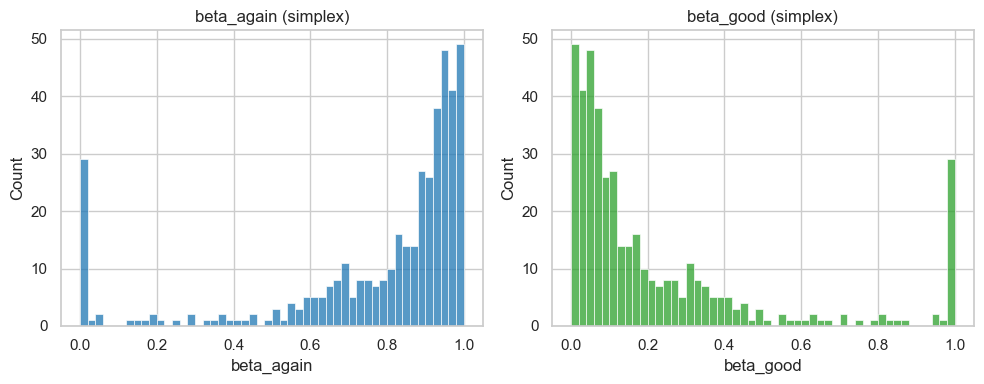

In [11]:
# Per-user constrained coefficients on the simplex: betas in [0,1], sum=1
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

EPS = 1e-12

records = []
for _, row in stability_df.iterrows():
    x1 = float(row["stability_again"])
    x2 = float(row["stability_good"])
    y = float(row["stability_hard"])

    if not np.isfinite(x1) or not np.isfinite(x2) or not np.isfinite(y):
        continue

    if abs(x1 - x2) < EPS:
        b = 0.5
    else:
        b = (y - x2) / (x1 - x2)  # unconstrained minimizer
        b = float(np.clip(b, 0.0, 1.0))

    b_again = b
    b_good = 1.0 - b

    records.append(
        {
            "user": row["user"],
            "beta_again": b_again,
            "beta_good": b_good,
            "beta_sum": b_again + b_good,
            "x_again": x1,
            "x_good": x2,
            "y_hard": y,
        }
    )

beta_simplex_df = pd.DataFrame(records)

print("Per-user constrained coefficients on [0,1] with sum=1")
print(beta_simplex_df[["beta_again", "beta_good", "beta_sum"]].describe())
print("\nWithin [0,1] check:")
inside = (beta_simplex_df["beta_again"].between(0, 1)) & (
    beta_simplex_df["beta_good"].between(0, 1)
)
print(f"Proportion inside bounds: {inside.mean():.6f}")

# Plots
sns.set(style="whitegrid")
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(beta_simplex_df["beta_again"], bins=50, color="#1f77b4")
plt.title("beta_again (simplex)")
plt.xlabel("beta_again")
plt.subplot(1, 2, 2)
sns.histplot(beta_simplex_df["beta_good"], bins=50, color="#2ca02c")
plt.title("beta_good (simplex)")
plt.xlabel("beta_good")
plt.tight_layout()
plt.show()